<a href="https://colab.research.google.com/github/Daniel220503/Machine-Learning-2026-Agost-Dic/blob/main/Hands_on_5_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on 5: Clasificadores Lineales — Support Vector Machines (SVM)

**Modalidad:** personal  
**Herramientas:** Python, NumPy, pandas, Matplotlib, seaborn y scikit-learn


**Martinez Romero Alberto Daniel**


## Objetivo
Mostrar **paso a paso** cómo implementar una **SVM** con scikit-learn, siguiendo el *pipeline* de Machine Learning y **contrastándola con el Perceptrón** (Hands-on 4).

## Caso de estudio
Dataset **Iris** (incluido en scikit-learn). Clasificaremos **Iris versicolor** (clase 0) contra **Iris virginica** (clase 1) usando **largo y ancho del pétalo**. A diferencia de setosa vs versicolor (totalmente separables), estas dos especies **se traslapan ligeramente**, lo que hace visible la diferencia entre una SVM y un Perceptrón.

## Contenido
1. Fundamentos teóricos de la SVM
2. Modelo matemático
3. Contraste teórico: SVM vs Perceptrón
4. Pipeline de Machine Learning
   - 4.1 Recolección de datos
   - 4.2 Descripción y análisis del dataset
   - 4.3 Scatter plot
   - 4.4 Preparación de los datos
   - 4.5 Entrenamiento de la SVM
   - 4.6 Frontera de decisión, margen y vectores de soporte
   - 4.7 Efecto del hiperparámetro C
   - 4.8 Entrenamiento del Perceptrón (para contrastar)
   - 4.9 Predicción
   - 4.10 Evaluación (métricas) y comparación final
5. Conclusiones

## 1. Fundamentos teóricos de la SVM

**¿Qué es?** Una *Support Vector Machine* (Máquina de Vectores de Soporte) es un algoritmo de **aprendizaje supervisado** usado principalmente para **clasificación** (también existe para regresión, SVR). Fue desarrollada por Vladimir Vapnik y colaboradores en los años 90.

**Idea central:** al igual que el Perceptrón, busca un **hiperplano** (una recta en 2D) que separe las clases. Pero hay infinitas rectas que separan datos separables; la SVM elige **la mejor**: la que deja el **mayor margen** posible entre las dos clases.

**Conceptos clave:**

| Concepto | Significado |
|---|---|
| **Hiperplano** | Frontera de decisión que separa las clases (una recta en 2D, un plano en 3D...) |
| **Margen** | Distancia entre el hiperplano y los puntos más cercanos de cada clase. La SVM lo **maximiza** |
| **Vectores de soporte** | Los puntos más cercanos al hiperplano. **Son los únicos que lo definen**: si se eliminan los demás puntos, la frontera no cambia |
| **Margen duro (*hard margin*)** | No permite ningún error de clasificación; solo funciona con datos perfectamente separables |
| **Margen suave (*soft margin*)** | Permite algunos errores o puntos dentro del margen; sirve para datos que se traslapan |
| **Hiperparámetro C** | Controla el equilibrio entre un margen ancho y pocos errores |
| **Kernel** | Truco matemático que permite separar datos **no lineales** proyectándolos a un espacio de mayor dimensión |

**El papel de C:**
- **C pequeño** → margen ancho, tolera más errores (modelo más simple, menor riesgo de sobreajuste).
- **C grande** → margen angosto, penaliza mucho los errores (modelo más ajustado a los datos, mayor riesgo de sobreajuste).

**Kernels comunes:** lineal (`linear`), polinomial (`poly`), gaussiano o RBF (`rbf`) y sigmoide. En este tutorial usamos el **kernel lineal**, porque el tema es *clasificadores lineales*.

**Ventajas:** funciona bien con pocos datos, es efectivo en espacios de muchas dimensiones, la frontera depende solo de unos cuantos puntos y tiene solución única.

**Desventajas:** es sensible a la escala de las variables, se vuelve lento con datasets muy grandes y no entrega probabilidades directamente.

## 2. Modelo matemático

> Como pide la actividad, aquí se presenta **solo el modelo**, sin el desarrollo analítico (no se deriva la solución).

**Función de decisión** (la misma forma que el Perceptrón):

$$f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x} + b$$

**Regla de clasificación:**

$$\hat{y} = \begin{cases} 1 & \text{si } f(\mathbf{x}) \ge 0 \\ 0 & \text{si } f(\mathbf{x}) < 0 \end{cases}$$

**Hiperplano y márgenes.** Con etiquetas $y_i \in \{-1,+1\}$, la frontera es $f(\mathbf{x})=0$ y los bordes del margen son:

$$f(\mathbf{x}) = +1 \qquad\text{y}\qquad f(\mathbf{x}) = -1$$

**Ancho del margen:**

$$\text{margen} = \frac{2}{\lVert\mathbf{w}\rVert}$$

Maximizar el margen equivale a **minimizar** $\lVert\mathbf{w}\rVert$.

**Problema de optimización (margen suave):**

$$\min_{\mathbf{w},\,b,\,\xi}\;\; \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_{i=1}^{m}\xi_i \qquad \text{sujeto a}\quad y_i(\mathbf{w}^\top\mathbf{x}_i + b)\ge 1-\xi_i,\;\; \xi_i\ge 0$$

- $\frac{1}{2}\lVert\mathbf{w}\rVert^2$: busca el **margen más ancho**.
- $\xi_i$ (variables de holgura): cuánto se "viola" el margen en el punto $i$.
- $C$: peso de las violaciones frente al ancho del margen.

**Forma equivalente con pérdida *hinge*:**

$$J(\mathbf{w},b) = \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_{i=1}^{m}\max\left(0,\;1-y_i f(\mathbf{x}_i)\right)$$

**Métricas de evaluación:**

$$Accuracy=\frac{VP+VN}{VP+VN+FP+FN} \quad Precision=\frac{VP}{VP+FP} \quad Recall=\frac{VP}{VP+FN} \quad F1=2\cdot\frac{Precision\cdot Recall}{Precision+Recall}$$

## 3. Contraste teórico: SVM vs Perceptrón

| Característica | Perceptrón | SVM (lineal) |
|---|---|---|
| **Tipo de modelo** | Clasificador lineal | Clasificador lineal |
| **Función de decisión** | $\mathbf{w}^\top\mathbf{x}+b$ | $\mathbf{w}^\top\mathbf{x}+b$ |
| **Objetivo** | Encontrar **cualquier** hiperplano que separe las clases | Encontrar **el** hiperplano de **máximo margen** |
| **Función de pérdida** | Error de clasificación (actualiza solo cuando se equivoca) | Pérdida *hinge* + regularización $\lVert\mathbf{w}\rVert^2$ |
| **Solución** | **No única**: depende del orden de los datos y de la inicialización | **Única** (problema convexo) |
| **Datos no separables** | **No converge** (oscila) | Funciona gracias al **margen suave** (parámetro C) |
| **Qué puntos influyen** | Todos los que se clasifican mal durante el entrenamiento | Solo los **vectores de soporte** |
| **Generalización** | Puede quedar muy cerca de una clase | El margen amplio suele generalizar mejor |
| **Datos no lineales** | No puede | Sí, con **kernels** |
| **Hiperparámetros** | Tasa de aprendizaje, épocas | C, kernel (y parámetros del kernel) |
| **Costo computacional** | Muy bajo, entrena rápido | Mayor, sobre todo con muchos datos |

**Resumen:** la SVM puede verse como un **Perceptrón mejorado**: usa la misma forma de frontera, pero en lugar de conformarse con la primera recta que separe los datos, busca la **más segura**. En la sección 4 lo comprobamos con datos reales.

## 4. Pipeline de Machine Learning

Etapas: **recolección → descripción/análisis → visualización → preparación → entrenamiento → predicción → evaluación**.

### 4.0 Importación de librerías

In [ ]:
import numpy as np                                     # NumPy: operaciones numéricas y matrices
import pandas as pd                                    # pandas: manejo de datos en tablas (DataFrame)
import matplotlib.pyplot as plt                        # Matplotlib: gráficas
import seaborn as sns                                  # seaborn: gráficas estadísticas
from sklearn.datasets import load_iris                 # Carga el dataset Iris incluido en scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score  # Dividir datos y validación cruzada
from sklearn.preprocessing import StandardScaler       # Estandariza las características
from sklearn.pipeline import make_pipeline             # Encadena escalado + modelo en un solo objeto
from sklearn.svm import SVC                            # Support Vector Classifier (la SVM de scikit-learn)
from sklearn.linear_model import Perceptron            # Perceptrón (para contrastar)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,  # Métricas de clasificación
                             f1_score, confusion_matrix, classification_report)  # Matriz y reporte

np.random.seed(42)                                     # Semilla para resultados reproducibles
plt.rcParams["figure.figsize"] = (7, 5)                # Tamaño por defecto de las gráficas

### 4.1 Recolección de datos
Cargamos Iris y nos quedamos con las especies **versicolor (1)** y **virginica (2)**, renombradas como clases **0** y **1**, y con las dos medidas del pétalo.

In [ ]:
iris = load_iris()                                          # Carga el dataset Iris (150 flores, 3 especies)
df_completo = pd.DataFrame(iris.data,                       # Convierte las medidas en un DataFrame
                           columns=iris.feature_names)      # Con los nombres originales de las columnas
df_completo["especie"] = iris.target                        # Agrega la especie (0, 1 o 2)

df = df_completo[df_completo["especie"] > 0].copy()         # Filtra: solo versicolor (1) y virginica (2)
df = df[["petal length (cm)", "petal width (cm)", "especie"]]  # Conserva largo/ancho del pétalo y la clase
df.columns = ["largo_petalo", "ancho_petalo", "especie"]    # Renombra las columnas
df["especie"] = df["especie"] - 1                           # Reetiqueta: versicolor = 0, virginica = 1
nombres_clase = {0: "versicolor", 1: "virginica"}           # Diccionario número → nombre de clase
df.head(10)                                                 # Muestra las primeras 10 filas

,largo_petalo,ancho_petalo,especie
50,4.7,1.4,0
51,4.5,1.5,0
52,4.9,1.5,0
53,4.0,1.3,0
54,4.6,1.5,0
55,4.5,1.3,0
56,4.7,1.6,0
57,3.3,1.0,0
58,4.6,1.3,0
59,3.9,1.4,0


### 4.2 Descripción y análisis del dataset

In [ ]:
print("Dimensiones (filas, columnas):", df.shape)            # Cantidad de observaciones y columnas
print("\nValores nulos por columna:")                        # Encabezado informativo
print(df.isnull().sum())                                     # Cuenta valores faltantes por columna
print("\nDistribución de clases:")                           # Encabezado informativo
print(df["especie"].map(nombres_clase).value_counts())       # Cuántas flores hay de cada clase (balance)

Dimensiones (filas, columnas): (100, 3)

Valores nulos por columna:
largo_petalo    0
ancho_petalo    0
especie         0
dtype: int64

Distribución de clases:
especie
versicolor    50
virginica     50
Name: count, dtype: int64


In [ ]:
df.groupby("especie")[["largo_petalo", "ancho_petalo"]].describe().T  # Estadísticos descriptivos por clase

especie                     0          1
largo_petalo count  50.000000  50.000000
             mean    4.260000   5.552000
             std     0.469911   0.551895
             min     3.000000   4.500000
             25%     4.000000   5.100000
             50%     4.350000   5.550000
             75%     4.600000   5.875000
             max     5.100000   6.900000
ancho_petalo count  50.000000  50.000000
             mean    1.326000   2.026000
             std     0.197753   0.274650
             min     1.000000   1.400000
             25%     1.200000   1.800000
             50%     1.300000   2.000000
             75%     1.500000   2.300000
             max     1.800000   2.500000

**Interpretación:** las clases están balanceadas (50/50) y no hay nulos. Las medias de virginica son mayores que las de versicolor, pero los rangos **se traslapan** (por ejemplo, el largo de pétalo de versicolor llega hasta 5.1 cm y el de virginica empieza en 4.5 cm), así que habrá una zona de mezcla.

### 4.3 Scatter plot (diagrama de dispersión)

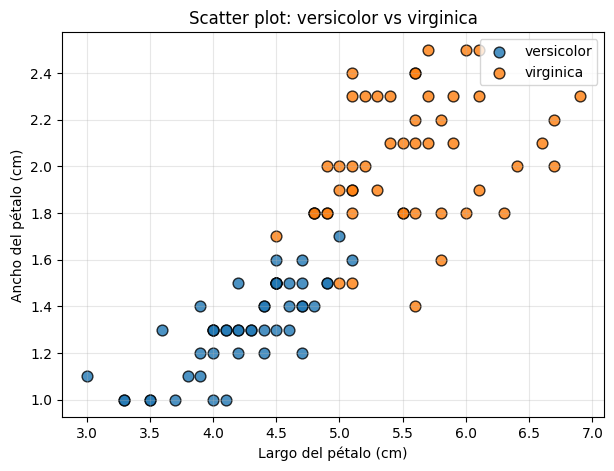

In [ ]:
for clase, color in zip([0, 1], ["tab:blue", "tab:orange"]):       # Recorre cada clase con su color
    sub = df[df["especie"] == clase]                               # Filtra las flores de esa clase
    plt.scatter(sub["largo_petalo"], sub["ancho_petalo"],          # Dibuja largo (X) vs ancho (Y)
                color=color, edgecolor="k", s=60, alpha=0.8,       # Color, borde negro, tamaño y transparencia
                label=nombres_clase[clase])                        # Etiqueta para la leyenda
plt.xlabel("Largo del pétalo (cm)")                                # Etiqueta del eje X
plt.ylabel("Ancho del pétalo (cm)")                                # Etiqueta del eje Y
plt.title("Scatter plot: versicolor vs virginica")                 # Título
plt.legend()                                                       # Leyenda
plt.grid(alpha=0.3)                                                # Cuadrícula suave
plt.show()                                                         # Muestra la gráfica

**Observación:** hay dos grupos con tendencia clara, pero **en el centro algunos puntos se mezclan**. Una recta casi los separa, pero no sin errores. Este es el escenario ideal para comparar: el Perceptrón no podrá converger del todo y la SVM usará su **margen suave**.

### 4.4 Preparación de los datos
1. Separar características (**X**) y etiqueta (**y**).
2. Dividir en entrenamiento (70%) y prueba (30%), estratificando por clase.
3. Estandarizar las características (la SVM es muy sensible a la escala porque trabaja con distancias).

In [ ]:
X = df[["largo_petalo", "ancho_petalo"]].values                  # Matriz de características (100 × 2)
y = df["especie"].values                                         # Vector de etiquetas (0 o 1)

X_train, X_test, y_train, y_test = train_test_split(             # Divide en entrenamiento y prueba
    X, y, test_size=0.3, random_state=42, stratify=y)            # 30% prueba; semilla fija; conserva proporción de clases
print("Entrenamiento:", X_train.shape[0], "| Prueba:", X_test.shape[0])  # Tamaño de cada conjunto

Entrenamiento: 70 | Prueba: 30


In [ ]:
scaler = StandardScaler()                                        # Crea el estandarizador (media 0, desviación 1)
X_train_s = scaler.fit_transform(X_train)                        # Aprende media/desviación del entrenamiento y transforma
X_test_s = scaler.transform(X_test)                              # Aplica la misma transformación a la prueba
print("Media entrenamiento escalado:", X_train_s.mean(axis=0).round(4))  # Debe ser ≈ 0
print("Desv. entrenamiento escalado:", X_train_s.std(axis=0).round(4))   # Debe ser ≈ 1

Media entrenamiento escalado: [0. 0.]
Desv. entrenamiento escalado: [1. 1.]


### 4.5 Entrenamiento de la SVM

Usamos `SVC` con **kernel lineal**. Hiperparámetros principales:
- `kernel="linear"`: frontera lineal (hiperplano).
- `C=1.0`: equilibrio entre margen ancho y errores.
- `random_state`: semilla para reproducibilidad.

In [ ]:
svm = SVC(kernel="linear", C=1.0, random_state=42)               # Crea la SVM lineal con C = 1
svm.fit(X_train_s, y_train)                                      # ENTRENA la SVM con los datos estandarizados

w = svm.coef_[0]                                                 # Vector de pesos w del hiperplano
b = svm.intercept_[0]                                            # Sesgo b del hiperplano
print("Pesos (w):", w.round(4))                                  # Muestra los pesos aprendidos
print("Sesgo (b):", round(b, 4))                                 # Muestra el sesgo aprendido
print("Ancho del margen 2/||w||:", round(2 / np.linalg.norm(w), 4))  # Ancho del margen (en unidades estandarizadas)
print("Número de vectores de soporte por clase:", svm.n_support_)    # Cuántos puntos definen la frontera
print("Total de vectores de soporte:", svm.n_support_.sum(), "de", len(X_train_s), "puntos")  # Comparado con el total

Pesos (w): [0.9762 1.837 ]
Sesgo (b): 0.3828
Ancho del margen 2/||w||: 0.9614
Número de vectores de soporte por clase: [6 6]
Total de vectores de soporte: 12 de 70 puntos


**Lectura:** de todos los puntos de entrenamiento, **solo unos pocos son vectores de soporte**. Únicamente ellos determinan la frontera; el resto de los puntos podría eliminarse sin cambiarla. Esto contrasta con el Perceptrón, donde todo error influye.

### 4.6 Frontera de decisión, margen y vectores de soporte
Dibujamos la frontera ($f(\mathbf{x})=0$, línea continua), los bordes del margen ($f(\mathbf{x})=\pm1$, líneas punteadas) y resaltamos los vectores de soporte con un círculo.

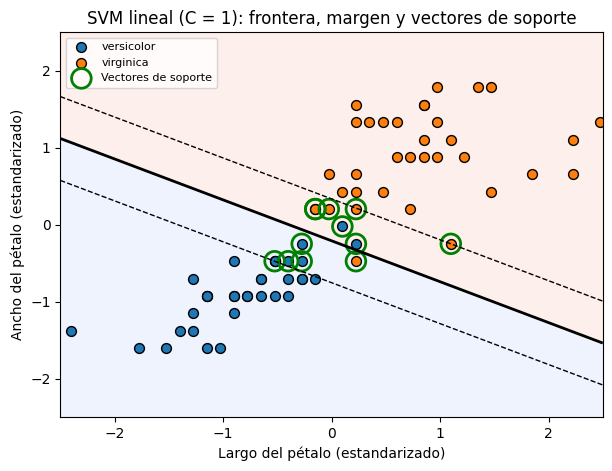

In [ ]:
def graficar_svm(clf, X_est, y_real, titulo, ax=None):                   # Función reutilizable para graficar la SVM
    if ax is None:                                                       # Si no se recibe un eje de gráfica...
        ax = plt.gca()                                                   # ...se usa el eje actual
    xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 300),                    # Malla de puntos que cubre el plano estandarizado
                         np.linspace(-2.5, 2.5, 300))                    # (300 × 300 puntos)
    zz = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)  # f(x) en cada punto de la malla
    ax.contourf(xx, yy, zz, levels=[-100, 0, 100], alpha=0.15, cmap="coolwarm")  # Colorea las dos regiones de decisión
    ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors="k",                # Dibuja f=-1, f=0 y f=+1
               linestyles=["--", "-", "--"], linewidths=[1, 2, 1])       # Punteada en los márgenes, continua en la frontera
    for clase, color in zip([0, 1], ["tab:blue", "tab:orange"]):         # Recorre cada clase
        m = y_real == clase                                              # Máscara de los puntos de esa clase
        ax.scatter(X_est[m, 0], X_est[m, 1], color=color, edgecolor="k", # Dibuja los puntos de la clase
                   s=50, label=nombres_clase[clase])                     # Con borde negro y etiqueta
    if hasattr(clf, "support_vectors_"):                                 # Si el modelo tiene vectores de soporte...
        ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],  # ...los dibuja encima
                   s=200, facecolors="none", edgecolors="green",         # Como círculos verdes sin relleno
                   linewidths=2, label="Vectores de soporte")            # Con su etiqueta
    ax.set_xlim(-2.5, 2.5)                                               # Límites del eje X
    ax.set_ylim(-2.5, 2.5)                                               # Límites del eje Y
    ax.set_xlabel("Largo del pétalo (estandarizado)")                    # Etiqueta del eje X
    ax.set_ylabel("Ancho del pétalo (estandarizado)")                    # Etiqueta del eje Y
    ax.set_title(titulo)                                                 # Título recibido como parámetro
    ax.legend(loc="upper left", fontsize=8)                              # Leyenda compacta

graficar_svm(svm, X_train_s, y_train, "SVM lineal (C = 1): frontera, margen y vectores de soporte")  # Grafica la SVM
plt.show()                                                               # Muestra la gráfica

### 4.7 Efecto del hiperparámetro C
Entrenamos tres SVM con C = 0.01, 1 y 100 para ver cómo cambia el margen.

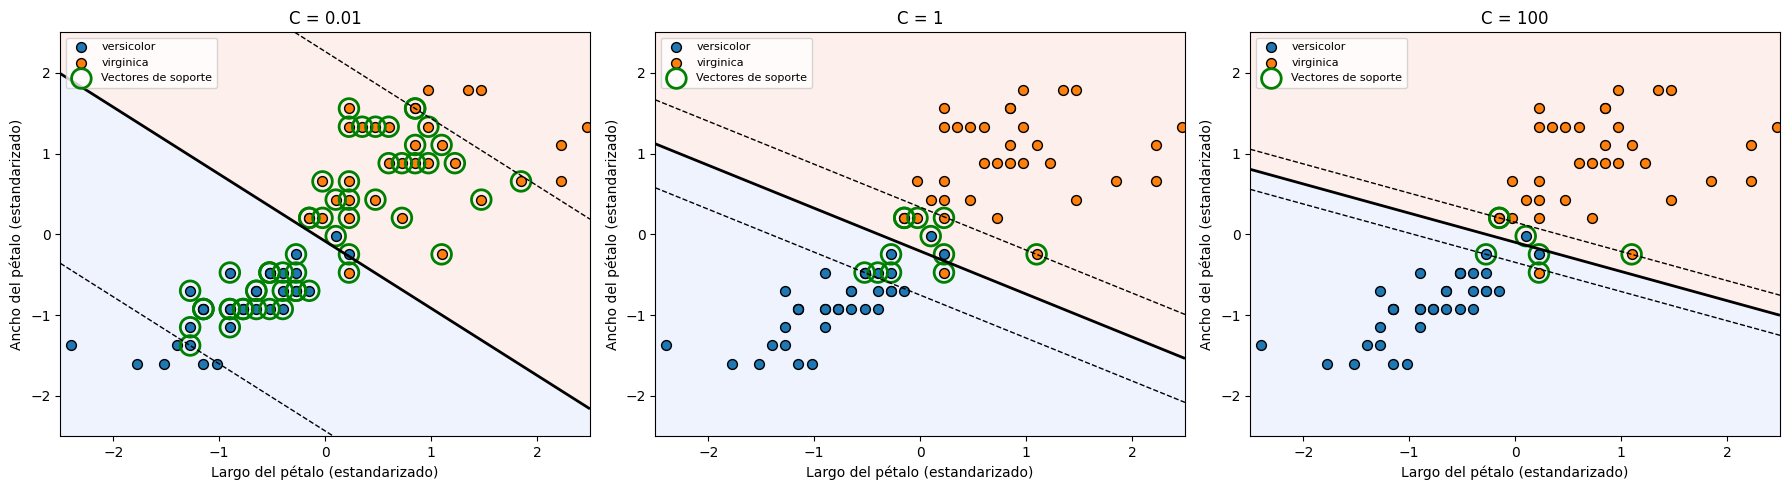

,C,Ancho del margen,Vectores de soporte,Accuracy train,Accuracy test
0,0.01,3.6140,58,0.9571,0.9000
1,1.00,0.9614,12,0.9571,0.8667
2,100.00,0.4669,7,0.9714,0.8667


In [ ]:
valores_C = [0.01, 1, 100]                                              # Valores de C a comparar (pequeño, medio, grande)
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))                         # Figura con 3 gráficas en una fila
filas = []                                                              # Lista para guardar el resumen de cada modelo

for ax, C in zip(ejes, valores_C):                                      # Recorre cada eje con su valor de C
    m = SVC(kernel="linear", C=C, random_state=42).fit(X_train_s, y_train)  # Entrena una SVM con ese C
    graficar_svm(m, X_train_s, y_train, f"C = {C}", ax=ax)              # Grafica frontera, márgenes y vectores
    filas.append({                                                      # Guarda las estadísticas del modelo
        "C": C,                                                         # Valor de C
        "Ancho del margen": 2 / np.linalg.norm(m.coef_[0]),             # Ancho = 2/||w||
        "Vectores de soporte": int(m.n_support_.sum()),                 # Cantidad de vectores de soporte
        "Accuracy train": m.score(X_train_s, y_train),                  # Exactitud en entrenamiento
        "Accuracy test": m.score(X_test_s, y_test)                      # Exactitud en prueba
    })

plt.tight_layout()                                                      # Ajusta los espacios entre gráficas
plt.show()                                                              # Muestra las gráficas
pd.DataFrame(filas).round(4)                                            # Tabla resumen del efecto de C

**Lectura:** a medida que **C crece**, el margen se vuelve **más angosto** y hay **menos vectores de soporte**; el modelo se ajusta más a los datos de entrenamiento. Con **C pequeño**, el margen es ancho y se toleran más puntos dentro de él. Un valor intermedio suele ser el mejor equilibrio.

### 4.8 Entrenamiento del Perceptrón (para contrastar)
Entrenamos Perceptrones con **distintas semillas** (`random_state`), que cambian el orden en que se leen los datos. Como el Perceptrón no busca el "mejor" hiperplano sino **cualquiera** que reduzca el error, cada semilla produce **una frontera diferente**.

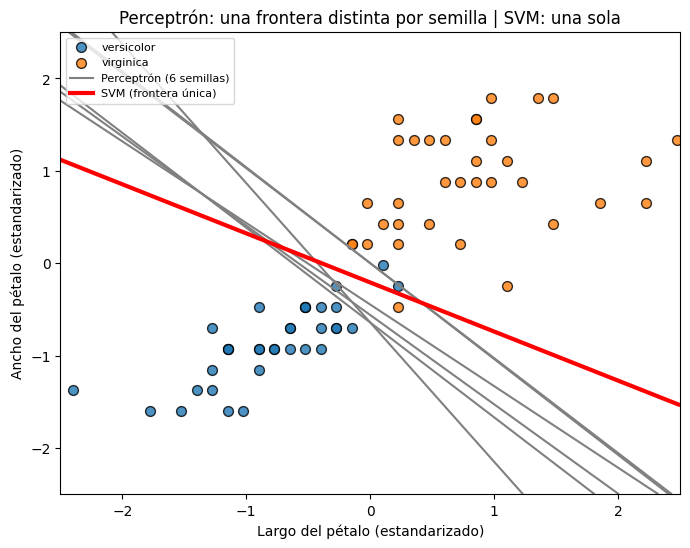

In [ ]:
semillas = [0, 1, 2, 3, 4, 5]                                           # Semillas distintas para el Perceptrón
perceptrones = []                                                       # Lista donde guardaremos los modelos entrenados

xx, yy = np.meshgrid(np.linspace(-2.5, 2.5, 300),                       # Malla de puntos para dibujar las fronteras
                     np.linspace(-2.5, 2.5, 300))                       # (300 × 300 puntos)
malla = np.c_[xx.ravel(), yy.ravel()]                                   # Convierte la malla en una lista de puntos (x, y)

plt.figure(figsize=(8, 6))                                              # Nueva figura más grande
for clase, color in zip([0, 1], ["tab:blue", "tab:orange"]):            # Recorre cada clase
    m = y_train == clase                                                # Máscara de la clase
    plt.scatter(X_train_s[m, 0], X_train_s[m, 1], color=color,          # Dibuja los puntos de entrenamiento
                edgecolor="k", s=50, alpha=0.8, label=nombres_clase[clase])  # Con borde y etiqueta

for s in semillas:                                                      # Recorre cada semilla
    p = Perceptron(eta0=0.1, max_iter=1000, tol=1e-3, random_state=s)   # Crea un Perceptrón con esa semilla
    p.fit(X_train_s, y_train)                                           # Lo entrena
    perceptrones.append(p)                                              # Lo guarda en la lista
    zz = p.decision_function(malla).reshape(xx.shape)                   # Calcula z = w·x + b en la malla
    plt.contour(xx, yy, zz, levels=[0], colors="gray",                  # Dibuja la frontera z = 0
                linestyles="-", linewidths=1.5)                         # En gris para distinguirla

zz_svm = svm.decision_function(malla).reshape(xx.shape)                 # Calcula f(x) de la SVM en la misma malla
plt.contour(xx, yy, zz_svm, levels=[0], colors="red", linewidths=3)     # Dibuja la frontera de la SVM en rojo grueso
plt.plot([], [], color="gray", label="Perceptrón (6 semillas)")         # Entrada de leyenda para las líneas grises
plt.plot([], [], color="red", linewidth=3, label="SVM (frontera única)")  # Entrada de leyenda para la línea roja
plt.xlim(-2.5, 2.5)                                                     # Límites del eje X
plt.ylim(-2.5, 2.5)                                                     # Límites del eje Y
plt.xlabel("Largo del pétalo (estandarizado)")                          # Etiqueta del eje X
plt.ylabel("Ancho del pétalo (estandarizado)")                          # Etiqueta del eje Y
plt.title("Perceptrón: una frontera distinta por semilla | SVM: una sola")  # Título
plt.legend(loc="upper left", fontsize=8)                                # Leyenda
plt.show()                                                              # Muestra la gráfica

In [ ]:
accs = [p.score(X_test_s, y_test) for p in perceptrones]                # Accuracy en prueba de cada Perceptrón
print("Accuracy en prueba por semilla (Perceptrón):", np.round(accs, 3))  # Muestra la variación entre semillas
print("Mínimo:", round(min(accs), 3), "| Máximo:", round(max(accs), 3))  # Rango de variación
print("Accuracy en prueba de la SVM (siempre igual):", round(svm.score(X_test_s, y_test), 3))  # Resultado de la SVM

Accuracy en prueba por semilla (Perceptrón): [0.9   0.9   0.9   0.9   0.933 0.867]
Mínimo: 0.867 | Máximo: 0.933
Accuracy en prueba de la SVM (siempre igual): 0.867


**Lectura:** el Perceptrón da **fronteras distintas y resultados variables** según la semilla, porque en datos con traslape **no converge** a una solución única. La SVM siempre obtiene **la misma frontera** (problema convexo con solución única).

### 4.9 Predicción

In [ ]:
y_pred_svm = svm.predict(X_test_s)                                      # Predicciones de la SVM sobre la prueba
perc = perceptrones[0]                                                  # Tomamos un Perceptrón (semilla 0) para comparar
y_pred_perc = perc.predict(X_test_s)                                    # Predicciones del Perceptrón sobre la prueba
print("Reales          :", y_test)                                      # Etiquetas verdaderas
print("Predichas (SVM) :", y_pred_svm)                                  # Predicciones de la SVM
print("Predichas (Perc):", y_pred_perc)                                 # Predicciones del Perceptrón

Reales          : [0 0 1 0 0 1 1 1 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 1 0 0 1 1 1 0]
Predichas (SVM) : [0 0 0 0 0 1 1 1 1 1 1 1 0 0 1 1 0 0 1 0 0 0 1 0 0 0 0 1 1 0]
Predichas (Perc): [0 0 1 0 0 1 1 1 1 1 1 1 0 0 1 1 0 0 1 0 0 0 1 1 1 1 1 1 1 0]


In [ ]:
flor_nueva = np.array([[4.9, 1.6]])                                     # Flor nueva: pétalo de 4.9 cm de largo y 1.6 cm de ancho
flor_nueva_s = scaler.transform(flor_nueva)                             # Se estandariza con el escalador del entrenamiento
f = svm.decision_function(flor_nueva_s)[0]                              # Valor f(x) de la SVM (distancia con signo a la frontera)
clase = svm.predict(flor_nueva_s)[0]                                    # Clase predicha por la SVM
print(f"f(x) = {f:.4f} → clase predicha por la SVM: {nombres_clase[clase]}")  # f<0 → versicolor; f≥0 → virginica
print("¿Dentro del margen (|f| < 1)?", abs(f) < 1)                      # Si está dentro del margen, la clasificación es poco segura

f(x) = -0.0976 → clase predicha por la SVM: versicolor
¿Dentro del margen (|f| < 1)? True


### 4.10 Evaluación de la técnica (métricas) y comparación final

In [ ]:
def metricas(y_real, y_est):                                            # Función que calcula las 4 métricas principales
    return [accuracy_score(y_real, y_est),                              # Exactitud
            precision_score(y_real, y_est),                             # Precisión
            recall_score(y_real, y_est),                                # Sensibilidad (recall)
            f1_score(y_real, y_est)]                                    # F1-score

comparacion = pd.DataFrame({                                            # Tabla comparativa de métricas en prueba
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-score"],         # Nombres de las métricas
    "SVM": metricas(y_test, y_pred_svm),                                # Métricas de la SVM
    "Perceptrón": metricas(y_test, y_pred_perc)                         # Métricas del Perceptrón
}).round(4)                                                             # Redondeo a 4 decimales
comparacion                                                             # Muestra la tabla

,Métrica,SVM,Perceptrón
0,Accuracy,0.8667,0.9000
1,Precision,0.9231,0.8333
2,Recall,0.8000,1.0000
3,F1-score,0.8571,0.9091


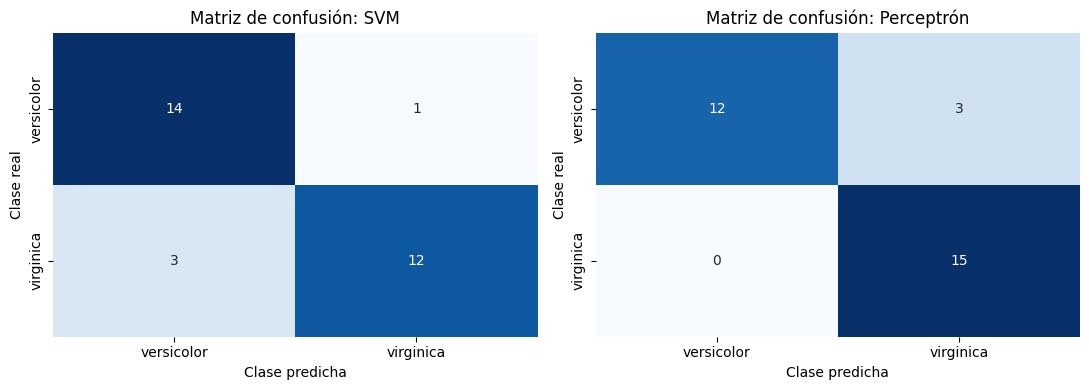

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))                         # Dos gráficas lado a lado
for ax, pred, nombre in zip(ejes, [y_pred_svm, y_pred_perc], ["SVM", "Perceptrón"]):  # Una matriz por modelo
    cm = confusion_matrix(y_test, pred)                                 # Calcula la matriz de confusión
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,  # Dibuja la matriz como mapa de calor
                xticklabels=["versicolor", "virginica"],                # Etiquetas de columnas (predicho)
                yticklabels=["versicolor", "virginica"])                # Etiquetas de filas (real)
    ax.set_xlabel("Clase predicha")                                     # Etiqueta del eje X
    ax.set_ylabel("Clase real")                                         # Etiqueta del eje Y
    ax.set_title(f"Matriz de confusión: {nombre}")                      # Título con el nombre del modelo
plt.tight_layout()                                                      # Ajusta espacios
plt.show()                                                              # Muestra las gráficas

In [ ]:
print("Reporte de clasificación de la SVM (prueba):")                   # Encabezado informativo
print(classification_report(y_test, y_pred_svm,                         # Reporte completo por clase
                            target_names=["versicolor", "virginica"]))  # Con los nombres de las especies

Reporte de clasificación de la SVM (prueba):
              precision    recall  f1-score   support

  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.87        30
   macro avg       0.87      0.87      0.87        30
weighted avg       0.87      0.87      0.87        30



**Validación cruzada.** Una sola división train/test puede ser engañosa con tan pocos datos. Repetimos la evaluación con **validación cruzada de 5 particiones** sobre todo el dataset (el escalado se incluye dentro de un *pipeline* para evitar fuga de información).

In [ ]:
modelo_svm = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0))        # Pipeline: escalar y luego SVM
modelo_perc = make_pipeline(StandardScaler(),                                    # Pipeline: escalar y luego Perceptrón
                            Perceptron(eta0=0.1, max_iter=1000, tol=1e-3, random_state=0))  # Con semilla 0

cv_svm = cross_val_score(modelo_svm, X, y, cv=5, scoring="accuracy")             # Accuracy en 5 particiones (SVM)
cv_perc = cross_val_score(modelo_perc, X, y, cv=5, scoring="accuracy")           # Accuracy en 5 particiones (Perceptrón)

print("SVM        → media:", cv_svm.mean().round(4), "| desv.:", cv_svm.std().round(4))   # Resultado de la SVM
print("Perceptrón → media:", cv_perc.mean().round(4), "| desv.:", cv_perc.std().round(4)) # Resultado del Perceptrón

SVM        → media: 0.93 | desv.: 0.051
Perceptrón → media: 0.94 | desv.: 0.049


**Cómo leer los resultados:**
- La **matriz de confusión** muestra aciertos (diagonal) y errores (fuera de la diagonal) de cada modelo.
- La **validación cruzada** da una estimación más confiable: una **media alta y desviación baja** indican un modelo estable.
- **Observación honesta:** en este dataset pequeño la exactitud de ambos modelos es **muy parecida** (el Perceptrón incluso puede salir ligeramente mejor en alguna partición). La ventaja de la SVM no está en ganar siempre en accuracy, sino en que su **frontera es única, estable y de margen máximo**, mientras que el Perceptrón cambia con la semilla (sección 4.8).

## 5. Conclusiones

1. La **SVM** es un clasificador que busca el hiperplano de **máximo margen**; solo los **vectores de soporte** determinan la frontera.
2. Comparte con el Perceptrón la misma forma de función de decisión ($\mathbf{w}^\top\mathbf{x}+b$), pero **difiere en el objetivo**: el Perceptrón acepta cualquier recta que separe; la SVM elige la más robusta.
3. Con datos que **se traslapan** (versicolor vs virginica), el Perceptrón **no converge** y su frontera cambia con la semilla; la SVM obtiene **siempre la misma solución** gracias al margen suave.
4. El hiperparámetro **C** controla el equilibrio entre margen ancho (C pequeño, más tolerancia) y ajuste estricto (C grande, riesgo de sobreajuste).
5. Las métricas (accuracy, precision, recall, F1), las matrices de confusión y la validación cruzada permiten evaluar y comparar ambos modelos de forma confiable.
6. Para datos **no lineales** la SVM puede extenderse con **kernels** (RBF, polinomial), algo que el Perceptrón simple no puede hacer.

## Referencias
- Cortes, C. & Vapnik, V. (1995). *Support-vector networks*. Machine Learning, 20(3), 273–297.
- Rosenblatt, F. (1958). *The perceptron: a probabilistic model for information storage and organization in the brain*. Psychological Review, 65(6), 386–408.
- Fisher, R. A. (1936). *The use of multiple measurements in taxonomic problems* (dataset Iris).
- Pedregosa et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR 12, 2825–2830.